# SqueezeNet with K-Means Segmentation | 5-Model Comparison | Google Colab GPU

Pipeline:
1. GPU environment setup & optimisation
2. Mount Google Drive & load dataset
3. Split val folder → 100 validation + 60 test (class-balanced)
4. K-Means segmentation — channel analysis, then pre-cache all images to disk
5. Build tf.data pipeline with prefetch for zero GPU idle time
6. Train 5 SqueezeNet variants with different hyperparameters
7. Compare on validation set → select best model
8. 5-Fold Cross-Validation on best model (CELL 10b) ← NEW
9. Retrain best model on train + val (100) combined
10. Final evaluation on 60 test images

## 🍅 Tomato Leaf Disease Detection

In [ ]:
# ============================================================================
# CELL 1 — Google Drive Mount + GPU Setup
# ============================================================================
from google.colab import drive
drive.mount('/content/drive')

import os, gc
os.environ['CUDA_VISIBLE_DEVICES'] = '0'
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

import tensorflow as tf
print('TF version :', tf.__version__)
print('CUDA built :', tf.test.is_built_with_cuda())
gpus = tf.config.list_physical_devices('GPU')
print('GPU devices :', gpus)

if not gpus:
    print('\n⚠️ No GPU found. Go to Runtime → Change runtime type → GPU')
else:
    tf.config.experimental.set_memory_growth(gpus[0], True)
    print('\n✅ Memory growth enabled:', gpus[0].name)

    from tensorflow.keras import mixed_precision
    mixed_precision.set_global_policy('mixed_float16')
    print('✅ Mixed precision:', mixed_precision.global_policy().name)
    print('✅ XLA JIT enabled')

def print_vram(label=''):
    try:
        info = tf.config.experimental.get_memory_info('GPU:0')
        cur  = info['current'] / 1024**2
        peak = info['peak']    / 1024**2
        tag  = f' [{label}]' if label else ''
        print(f'  VRAM{tag} — current: {cur:.0f} MB | peak: {peak:.0f} MB')
    except Exception:
        pass

print_vram('baseline')

Mounted at /content/drive
TF version : 2.20.0
CUDA built : True
GPU devices : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

✅ Memory growth enabled: /physical_device:GPU:0
✅ Mixed precision: mixed_float16
✅ XLA JIT enabled
  VRAM [baseline] — current: 0 MB | peak: 0 MB


In [ ]:
# ============================================================================
# CELL 2 — Imports & Global Config
# ============================================================================
import os, gc
import numpy as np
import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
import seaborn as sns
import json
import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)
tf.random.set_seed(42)

# ── PATH CONFIG ───────────────────────────────────────────────────────────────
# ⚠️ Set IMAGES_DIR to the folder inside your Drive that contains train/ and val/
# Example: '/content/drive/MyDrive/dataset/final dataset/Images'
IMAGES_DIR = '/content/drive/MyDrive/Augmented_tomato_leaves/Images' # <-- CHANGE THIS
TRAIN_DIR  = os.path.join(IMAGES_DIR, 'train')
VAL_DIR    = os.path.join(IMAGES_DIR, 'val')

# Cache & output on Colab local disk (fast /content SSD; lost on disconnect)
CACHE_DIR  = '/content/cache'
OUTPUT_DIR = '/content/squeezenet_output'
os.makedirs(CACHE_DIR,  exist_ok=True)
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ── HYPERPARAMETERS ───────────────────────────────────────────────────────────
IMG_HEIGHT   = 224
IMG_WIDTH    = 224
IMG_CHANNELS = 3
BATCH_SIZE   = 32
EPOCHS       = 40
NUM_CLUSTERS = 3
VAL_IMAGES   = 60   # 50 Healthy + 50 Diseased
TEST_IMAGES  = 40    # 30 Healthy + 30 Diseased
CLASS_NAMES  = ['Healthy', 'Diseased']

print('✅ Config ready')
print(f'  TRAIN_DIR  : {TRAIN_DIR}')
print(f'  VAL_DIR    : {VAL_DIR}')
print(f'  CACHE_DIR  : {CACHE_DIR}')
print(f'  OUTPUT_DIR : {OUTPUT_DIR}')

✅ Config ready
  TRAIN_DIR  : /content/drive/MyDrive/Augmented_tomato_leaves/Images/train
  VAL_DIR    : /content/drive/MyDrive/Augmented_tomato_leaves/Images/val
  CACHE_DIR  : /content/cache
  OUTPUT_DIR : /content/squeezenet_output


In [ ]:
# ============================================================================
# CELL 3 — Dataset Loading
# Folder structure: train/Healthy, train/Diseased, val/Healthy, val/Diseased
# ============================================================================
def load_dataset_from_dir(directory):
    """
    Loads image paths and labels from a directory with sub-folders:
    directory/
      Healthy/  → label 0
      Diseased/ → label 1
    Returns: (image_paths, labels)
    """
    image_paths, labels = [], []
    label_map = {'Healthy': 0, 'Diseased': 1}
    for class_name, label in label_map.items():
        class_dir = os.path.join(directory, class_name)
        if not os.path.isdir(class_dir):
            print(f'  ⚠️ Folder not found: {class_dir}')
            continue
        files = sorted([
            f for f in os.listdir(class_dir)
            if f.lower().endswith(('.jpg', '.jpeg', '.png'))
        ])
        for fname in files:
            image_paths.append(os.path.join(class_dir, fname))
            labels.append(label)
        print(f'  {class_name:10s}: {len(files):5d} images')
    return np.array(image_paths), np.array(labels)

print('=' * 60)
print('📂 Loading TRAIN dataset')
print('=' * 60)
train_paths, train_labels = load_dataset_from_dir(TRAIN_DIR)
print(f'  → Total train images: {len(train_paths)}')

print('\n' + '=' * 60)
print('📂 Loading VAL dataset (will be split into val + test)')
print('=' * 60)
val_raw_paths, val_raw_labels = load_dataset_from_dir(VAL_DIR)
print(f'  → Total val images : {len(val_raw_paths)}')

📂 Loading TRAIN dataset
  Healthy   :   500 images
  Diseased  :   500 images
  → Total train images: 1000

📂 Loading VAL dataset (will be split into val + test)
  Healthy   :    50 images
  Diseased  :    50 images
  → Total val images : 100


📊 DATASET SPLIT SUMMARY
  Train :  1000 total | Healthy=500, Diseased=500
  Val   :    60 total | Healthy=30, Diseased=30
  Test  :    40 total | Healthy=20, Diseased=20


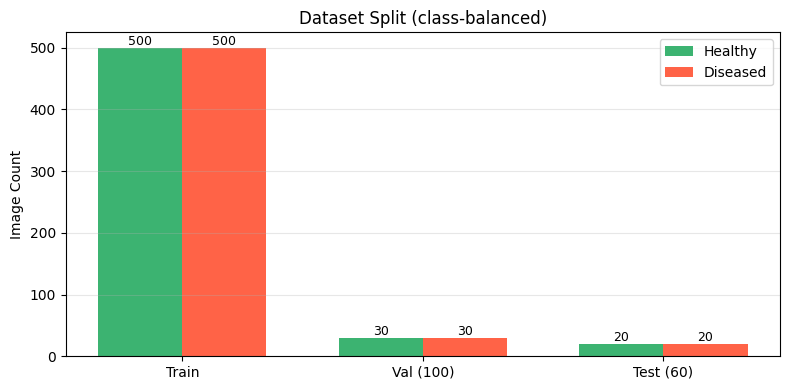

✅ dataset_split.png saved


In [ ]:
# ============================================================================
# CELL 4 — Balanced Val / Test Split
# 100 images for validation (50H + 50D)
# 60 images for test (30H + 30D)
# ============================================================================
def balanced_split(paths, labels, n_val, n_test, seed=42):
    rng = np.random.default_rng(seed)
    per_class_val  = n_val  // 2
    per_class_test = n_test // 2
    val_idx, test_idx = [], []
    for cls in [0, 1]:
        cls_indices = np.where(labels == cls)[0]
        shuffled    = rng.permutation(cls_indices)
        needed      = per_class_val + per_class_test
        if len(shuffled) < needed:
            raise ValueError(
                f'Class {cls} only has {len(shuffled)} images but needs {needed}.'
            )
        val_idx.extend( shuffled[:per_class_val].tolist())
        test_idx.extend(shuffled[per_class_val:per_class_val + per_class_test].tolist())
    val_idx  = np.array(val_idx)
    test_idx = np.array(test_idx)
    return (paths[val_idx],  labels[val_idx],
            paths[test_idx], labels[test_idx])

X_val, y_val, X_test, y_test = balanced_split(
    val_raw_paths, val_raw_labels, VAL_IMAGES, TEST_IMAGES
)
X_train, y_train = train_paths, train_labels

print('=' * 60)
print('📊 DATASET SPLIT SUMMARY')
print('=' * 60)
for name, paths, labels in [
    ('Train', X_train, y_train),
    ('Val',   X_val,   y_val),
    ('Test',  X_test,  y_test)
]:
    h = np.sum(labels == 0)
    d = np.sum(labels == 1)
    print(f'  {name:6s}: {len(paths):5d} total | Healthy={h}, Diseased={d}')

# Visualise split
fig, ax = plt.subplots(figsize=(8, 4))
splits   = ['Train', 'Val (100)', 'Test (60)']
healthy  = [np.sum(y_train==0), np.sum(y_val==0), np.sum(y_test==0)]
diseased = [np.sum(y_train==1), np.sum(y_val==1), np.sum(y_test==1)]
x = np.arange(len(splits)); w = 0.35
ax.bar(x - w/2, healthy,  w, label='Healthy',  color='mediumseagreen')
ax.bar(x + w/2, diseased, w, label='Diseased',  color='tomato')
ax.set_xticks(x); ax.set_xticklabels(splits)
ax.set_ylabel('Image Count'); ax.set_title('Dataset Split (class-balanced)')
ax.legend(); ax.grid(True, alpha=0.3, axis='y')
for i, (h, d) in enumerate(zip(healthy, diseased)):
    ax.text(i - w/2, h + 5, str(h), ha='center', fontsize=9)
    ax.text(i + w/2, d + 5, str(d), ha='center', fontsize=9)
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/dataset_split.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ dataset_split.png saved')

In [ ]:
# ============================================================================
# CELL 5 — K-Means Segmentation Functions
# ============================================================================
def load_image_rgb(path, size=(IMG_HEIGHT, IMG_WIDTH)):
    img = cv2.imread(path)
    if img is None:
        return None
    return cv2.cvtColor(cv2.resize(img, size), cv2.COLOR_BGR2RGB)

def analyze_channels(sample_paths, n_samples=60):
    """Score 9 colour channels by K-means cluster separation; return the best."""
    sample_paths  = sample_paths[:min(n_samples, len(sample_paths))]
    channel_names = ['red','green','blue','hue','saturation','value','l','a','b']
    scores = {ch: [] for ch in channel_names}
    for path in sample_paths:
        img = load_image_rgb(path)
        if img is None:
            continue
        hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)
        lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
        raw = {
            'red': img[:,:,0], 'green': img[:,:,1], 'blue': img[:,:,2],
            'hue': hsv[:,:,0], 'saturation': hsv[:,:,1], 'value': hsv[:,:,2],
            'l': lab[:,:,0],   'a': lab[:,:,1],           'b': lab[:,:,2]
        }
        for ch, data in raw.items():
            km = KMeans(n_clusters=3, random_state=42, n_init=5)
            km.fit(data.flatten().reshape(-1, 1))
            scores[ch].append(np.std(km.cluster_centers_.flatten()))
    mean_scores = {ch: np.mean(v) for ch, v in scores.items()}
    best = max(mean_scores, key=mean_scores.get)
    print('\n📊 Channel separation scores (higher = better):')
    for ch, sc in sorted(mean_scores.items(), key=lambda x: -x[1]):
        print(f'  {ch:12s}: {sc:.4f}{" ✅" if ch == best else ""}')
    print(f'\n→ Best channel: {best}')
    return best, mean_scores

def segment_image_kmeans(image, channel='green', n_clusters=NUM_CLUSTERS):
    """K-Means leaf segmentation. Returns (masked_img, mask, cluster_map, centres)."""
    if channel in ('red','green','blue'):
        ch_data = image[:,:, ('red','green','blue').index(channel)]
    elif channel in ('hue','saturation','value'):
        ch_data = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)[
            :,:, ('hue','saturation','value').index(channel)]
    else:
        ch_data = cv2.cvtColor(image, cv2.COLOR_RGB2LAB)[
            :,:, ('l','a','b').index(channel)]
    pixels = ch_data.flatten().reshape(-1,1).astype(np.float32)
    km  = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
    lbl = km.fit_predict(pixels).reshape(image.shape[:2])
    centres     = km.cluster_centers_.flatten()
    sorted_idx  = np.argsort(centres)
    leaf_cluster = sorted_idx[1] if n_clusters >= 3 else sorted_idx[0]
    mask = (lbl == leaf_cluster).astype(np.uint8) * 255
    k    = np.ones((5,5), np.uint8)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, k)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN,  k)
    masked = image.copy()
    masked[mask == 0] = 0
    return masked, mask, lbl, centres

print('⏳ Analysing colour channels on training samples…')
best_channel, ch_scores = analyze_channels(X_train)

⏳ Analysing colour channels on training samples…

📊 Channel separation scores (higher = better):
  saturation  : 56.2076 ✅
  red         : 49.9272
  blue        : 46.0907
  value       : 45.0536
  l           : 43.6288
  green       : 42.3992
  hue         : 26.4160
  a           : 14.0815
  b           : 13.4120

→ Best channel: saturation


In [ ]:
# ============================================================================
# CELL 5b — Pre-Cache Segmented Images to Disk
# ============================================================================
from concurrent.futures import ThreadPoolExecutor, as_completed

CACHE_KEY  = f'ch-{best_channel}_k{NUM_CLUSTERS}_{IMG_HEIGHT}x{IMG_WIDTH}'
CACHE_TRAIN  = os.path.join(CACHE_DIR, f'train_{CACHE_KEY}.npy')
CACHE_TRLBL  = os.path.join(CACHE_DIR, f'train_labels_{CACHE_KEY}.npy')
CACHE_VAL    = os.path.join(CACHE_DIR, f'val_{CACHE_KEY}.npy')
CACHE_VALLBL = os.path.join(CACHE_DIR, f'val_labels_{CACHE_KEY}.npy')
CACHE_TEST   = os.path.join(CACHE_DIR, f'test_{CACHE_KEY}.npy')
CACHE_TSTLBL = os.path.join(CACHE_DIR, f'test_labels_{CACHE_KEY}.npy')

def segment_one(args):
    idx, path, channel, img_size = args
    img = load_image_rgb(path, size=img_size)
    if img is None:
        return idx, np.zeros((*img_size, 3), dtype=np.float32)
    seg, _, _, _ = segment_image_kmeans(img, channel=channel, n_clusters=NUM_CLUSTERS)
    return idx, seg.astype(np.float32) / 255.0

def build_cache(paths, labels, cache_X, cache_y, split_name,
                channel, img_size=(IMG_HEIGHT, IMG_WIDTH), n_workers=4):
    if os.path.exists(cache_X) and os.path.exists(cache_y):
        print(f'  ✅ {split_name} cache found — loading from disk')
        return np.load(cache_X), np.load(cache_y)
    print(f'  ⏳ Building {split_name} cache ({len(paths)} images, {n_workers} threads)…')
    n = len(paths)
    X = np.zeros((n, *img_size, 3), dtype=np.float32)
    y = np.array(labels, dtype=np.int32)
    args_list = [(i, p, channel, img_size) for i, p in enumerate(paths)]
    done = 0
    with ThreadPoolExecutor(max_workers=n_workers) as pool:
        futures = {pool.submit(segment_one, a): a[0] for a in args_list}
        for fut in as_completed(futures):
            idx, arr = fut.result()
            X[idx]   = arr
            done    += 1
            if done % max(1, n // 10) == 0 or done == n:
                print(f'  {done}/{n} ({100*done//n}%)', end='\r')
    print(f'\n  Saving {split_name} cache → {cache_X}')
    np.save(cache_X, X)
    np.save(cache_y, y)
    size_mb = X.nbytes / 1024**2
    print(f'  ✅ {split_name}: {X.shape} ({size_mb:.0f} MB on disk)')
    return X, y

print(f'Cache key: {CACHE_KEY}\n')
X_train_c, y_train_c = build_cache(X_train, y_train, CACHE_TRAIN, CACHE_TRLBL, 'TRAIN', best_channel)
X_val_c,   y_val_c   = build_cache(X_val,   y_val,   CACHE_VAL,   CACHE_VALLBL, 'VAL',   best_channel)
X_test_c,  y_test_c  = build_cache(X_test,  y_test,  CACHE_TEST,  CACHE_TSTLBL, 'TEST',  best_channel)

total_mb = (X_train_c.nbytes + X_val_c.nbytes + X_test_c.nbytes) / 1024**2
print(f'\n✅ All caches ready. Total RAM used: {total_mb:.0f} MB')
print('  K-means will NOT run during training.')

Cache key: ch-saturation_k3_224x224

  ⏳ Building TRAIN cache (1000 images, 4 threads)…
  1000/1000 (100%)
  Saving TRAIN cache → /content/cache/train_ch-saturation_k3_224x224.npy
  ✅ TRAIN: (1000, 224, 224, 3) (574 MB on disk)
  ⏳ Building VAL cache (60 images, 4 threads)…
  60/60 (100%)
  Saving VAL cache → /content/cache/val_ch-saturation_k3_224x224.npy
  ✅ VAL: (60, 224, 224, 3) (34 MB on disk)
  ⏳ Building TEST cache (40 images, 4 threads)…
  40/40 (100%)
  Saving TEST cache → /content/cache/test_ch-saturation_k3_224x224.npy
  ✅ TEST: (40, 224, 224, 3) (23 MB on disk)

✅ All caches ready. Total RAM used: 632 MB
  K-means will NOT run during training.


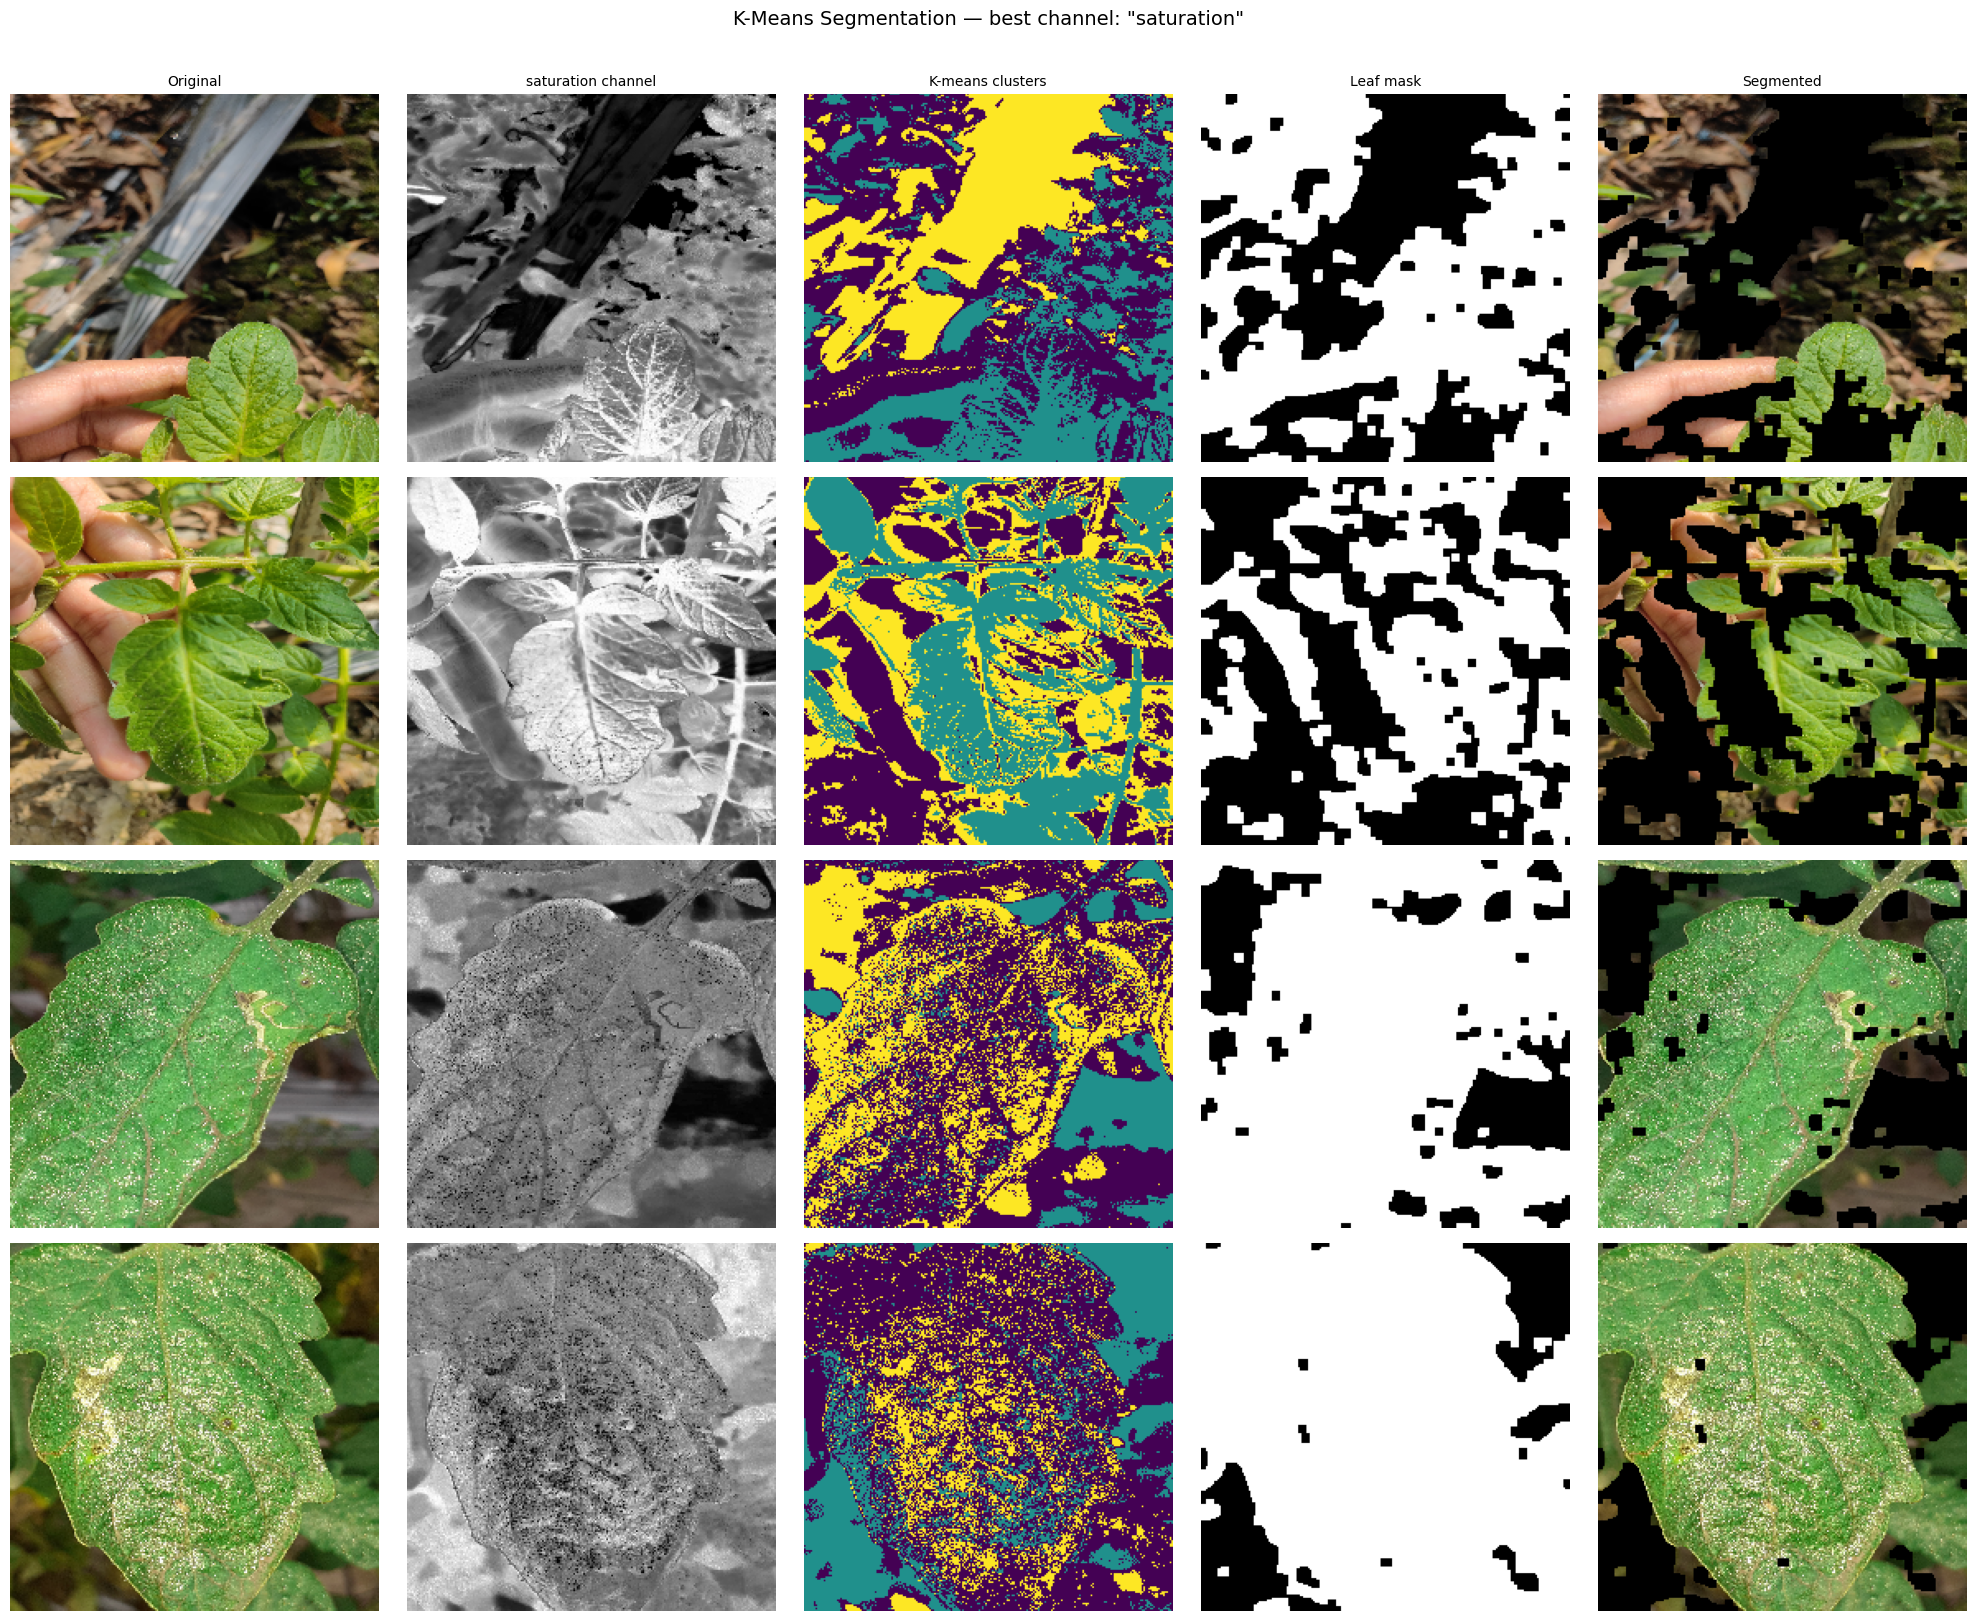

✅ segmentation_visualisation.png saved


In [ ]:
# ============================================================================
# CELL 6 — Segmentation Visualisation
# ============================================================================
def visualise_segmentation(paths, labels, channel, n_per_class=2):
    h_idx   = [i for i, l in enumerate(labels) if l == 0][:n_per_class]
    d_idx   = [i for i, l in enumerate(labels) if l == 1][:n_per_class]
    indices = h_idx + d_idx
    fig, axes = plt.subplots(len(indices), 5, figsize=(20, 4 * len(indices)))
    if len(indices) == 1:
        axes = axes.reshape(1, -1)
    col_titles = ['Original', f'{channel} channel', 'K-means clusters', 'Leaf mask', 'Segmented']
    for row, idx in enumerate(indices):
        img = load_image_rgb(paths[idx])
        if img is None:
            continue
        seg, mask, clustered, _ = segment_image_kmeans(img, channel=channel)
        cls_label = 'Healthy' if labels[idx] == 0 else 'Diseased'
        if channel in ('red','green','blue'):
            ch_img = img[:, :, ('red','green','blue').index(channel)]
        elif channel in ('hue','saturation','value'):
            ch_img = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)[
                :, :, ('hue','saturation','value').index(channel)]
        else:
            ch_img = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)[
                :, :, ('l','a','b').index(channel)]
        imgs  = [img, ch_img, clustered, mask, seg]
        cmaps = [None, 'gray', 'viridis', 'gray', None]
        for col in range(5):
            ax = axes[row, col]
            if cmaps[col]:
                ax.imshow(imgs[col], cmap=cmaps[col])
            else:
                ax.imshow(imgs[col].astype(np.uint8))
            title = col_titles[col] if row == 0 else ''
            if col == 0:
                ax.set_ylabel(cls_label, fontsize=11, fontweight='bold')
            ax.set_title(title, fontsize=10)
            ax.axis('off')
    plt.suptitle(f'K-Means Segmentation — best channel: "{channel}"', fontsize=14, y=1.01)
    plt.tight_layout()
    plt.savefig(f'{OUTPUT_DIR}/segmentation_visualisation.png', dpi=150, bbox_inches='tight')
    plt.show()
    print('✅ segmentation_visualisation.png saved')

visualise_segmentation(X_train, y_train, best_channel)

In [ ]:
# ============================================================================
# CELL 7 — tf.data Pipeline
# ============================================================================
AUTOTUNE = tf.data.AUTOTUNE

def augment_tf(image, label):
    image = tf.image.random_flip_left_right(image)
    image = tf.image.random_flip_up_down(image)
    image = tf.image.random_brightness(image, max_delta=0.15)
    image = tf.image.random_contrast(image, lower=0.8, upper=1.2)
    image = tf.image.random_saturation(image, lower=0.8, upper=1.2)
    image = tf.clip_by_value(image, 0.0, 1.0)
    return image, label

def make_dataset(X, y, batch_size=BATCH_SIZE, augment=False, shuffle=True):
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if shuffle:
        ds = ds.shuffle(buffer_size=len(X), reshuffle_each_iteration=True)
    if augment:
        ds = ds.map(augment_tf, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(batch_size, drop_remainder=False)
    ds = ds.prefetch(AUTOTUNE)
    return ds

train_ds = make_dataset(X_train_c, y_train_c, augment=True,  shuffle=True)
val_ds   = make_dataset(X_val_c,   y_val_c,   augment=False, shuffle=False)
test_ds  = make_dataset(X_test_c,  y_test_c,  augment=False, shuffle=False)

print('✅ tf.data pipelines built')
print(f'  train_ds : {len(X_train_c)} images → {len(list(train_ds))} batches')
print(f'  val_ds   : {len(X_val_c)}   images → {len(list(val_ds))} batches')
print(f'  test_ds  : {len(X_test_c)}  images → {len(list(test_ds))} batches')

✅ tf.data pipelines built
  train_ds : 1000 images → 32 batches
  val_ds   : 60   images → 2 batches
  test_ds  : 40  images → 2 batches


In [ ]:
# ============================================================================
# CELL 8 — SqueezeNet Building Blocks + 5 Model Definitions
# ============================================================================
# SqueezeNet uses "Fire modules" instead of plain conv blocks.
# A Fire module has:
#   squeeze layer : 1×1 convolutions  (compresses channels cheaply)
#   expand  layer : 1×1 + 3×3 convolutions concatenated  (re-expands)
# This gives VGG-level accuracy at ~50× fewer parameters.
#
# Reference: Iandola et al., "SqueezeNet" (2016) arXiv:1602.07360
# ============================================================================

INPUT_SHAPE = (IMG_HEIGHT, IMG_WIDTH, IMG_CHANNELS)

def fire_module(x, squeeze_filters, expand_filters, l2_lambda=1e-4):
    """
    SqueezeNet Fire module.
    squeeze_filters : number of 1×1 squeeze conv filters
    expand_filters  : number of filters for EACH of the 1×1 and 3×3 expand convs
                      (total expand output = 2 * expand_filters channels)
    """
    # ── Squeeze ───────────────────────────────────────────────────────────────
    x = layers.Conv2D(squeeze_filters, (1, 1), padding='same',
                      kernel_regularizer=regularizers.l2(l2_lambda))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)

    # ── Expand (two parallel branches, then concatenate) ──────────────────────
    e1 = layers.Conv2D(expand_filters, (1, 1), padding='same',
                       kernel_regularizer=regularizers.l2(l2_lambda))(x)
    e1 = layers.BatchNormalization()(e1)
    e1 = layers.Activation('relu')(e1)

    e3 = layers.Conv2D(expand_filters, (3, 3), padding='same',
                       kernel_regularizer=regularizers.l2(l2_lambda))(x)
    e3 = layers.BatchNormalization()(e3)
    e3 = layers.Activation('relu')(e3)

    return layers.Concatenate()([e1, e3])   # output: 2 * expand_filters channels


# ── Model 1 — Lightweight SqueezeNet ─────────────────────────────────────────
# Mirrors original SqueezeNet 1.0 structure but truncated for 224×224 binary task.
# Optimiser : Adam lr=1e-3 | Dropout=0.5
def build_model_1():
    """Lightweight SqueezeNet — 4 Fire modules [16/32, 16/32, 32/64, 32/64] | Adam lr=1e-3"""
    inp = keras.Input(shape=INPUT_SHAPE)

    # Stem conv (like SqueezeNet's conv1)
    x = layers.Conv2D(64, (3, 3), strides=2, padding='same',
                      kernel_regularizer=regularizers.l2(1e-4))(inp)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D(3, strides=2, padding='same')(x)

    # Fire modules — group 1
    x = fire_module(x, squeeze_filters=16, expand_filters=32,  l2_lambda=1e-4)
    x = fire_module(x, squeeze_filters=16, expand_filters=32,  l2_lambda=1e-4)
    x = layers.MaxPooling2D(3, strides=2, padding='same')(x)

    # Fire modules — group 2
    x = fire_module(x, squeeze_filters=32, expand_filters=64,  l2_lambda=1e-4)
    x = fire_module(x, squeeze_filters=32, expand_filters=64,  l2_lambda=1e-4)
    x = layers.MaxPooling2D(3, strides=2, padding='same')(x)

    x = layers.Dropout(0.5)(x)
    x = layers.GlobalAveragePooling2D()(x)
    out = layers.Dense(2, activation='softmax', dtype='float32')(x)

    m = keras.Model(inp, out, name='SqNet1_Lightweight')
    m.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return m


# ── Model 2 — Deeper SqueezeNet ───────────────────────────────────────────────
# More Fire modules + wider expand filters.
# Optimiser : Adam lr=5e-4 | Dropout=0.5
def build_model_2():
    """Deeper SqueezeNet — 6 Fire modules [16/64, 16/64, 32/128, 32/128, 48/192, 48/192] | Adam lr=5e-4"""
    inp = keras.Input(shape=INPUT_SHAPE)

    x = layers.Conv2D(96, (7, 7), strides=2, padding='same',
                      kernel_regularizer=regularizers.l2(1e-4))(inp)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D(3, strides=2, padding='same')(x)

    x = fire_module(x, 16, 64,  1e-4)
    x = fire_module(x, 16, 64,  1e-4)
    x = layers.MaxPooling2D(3, strides=2, padding='same')(x)

    x = fire_module(x, 32, 128, 1e-4)
    x = fire_module(x, 32, 128, 1e-4)
    x = layers.MaxPooling2D(3, strides=2, padding='same')(x)

    x = fire_module(x, 48, 192, 1e-4)
    x = fire_module(x, 48, 192, 1e-4)

    x = layers.Dropout(0.5)(x)
    x = layers.GlobalAveragePooling2D()(x)
    out = layers.Dense(2, activation='softmax', dtype='float32')(x)

    m = keras.Model(inp, out, name='SqNet2_Deeper')
    m.compile(optimizer=keras.optimizers.Adam(5e-4),
              loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return m


# ── Model 3 — Regularised SqueezeNet ─────────────────────────────────────────
# Heavy L2 + high dropout to fight overfitting on small dataset.
# Optimiser : Adam lr=1e-3 | L2=1e-3 | Dropout=0.6
def build_model_3():
    """Regularised SqueezeNet — 4 Fire modules | Adam lr=1e-3 | high L2=1e-3 + drop=0.6"""
    inp = keras.Input(shape=INPUT_SHAPE)

    x = layers.Conv2D(64, (3, 3), strides=2, padding='same',
                      kernel_regularizer=regularizers.l2(1e-3))(inp)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D(3, strides=2, padding='same')(x)

    x = fire_module(x, 32, 64,  1e-3)
    x = fire_module(x, 32, 64,  1e-3)
    x = layers.MaxPooling2D(3, strides=2, padding='same')(x)

    x = fire_module(x, 48, 96,  1e-3)
    x = fire_module(x, 48, 96,  1e-3)
    x = layers.MaxPooling2D(3, strides=2, padding='same')(x)

    x = layers.Dropout(0.6)(x)
    x = layers.GlobalAveragePooling2D()(x)
    out = layers.Dense(2, activation='softmax', dtype='float32')(x)

    m = keras.Model(inp, out, name='SqNet3_Regularised')
    m.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return m


# ── Model 4 — RMSprop SqueezeNet ──────────────────────────────────────────────
# Same topology as Model 1 but with RMSprop optimiser.
# Optimiser : RMSprop lr=5e-4 | Dropout=0.5
def build_model_4():
    """RMSprop SqueezeNet — 4 Fire modules [16/32, 16/32, 32/64, 32/64] | RMSprop lr=5e-4"""
    inp = keras.Input(shape=INPUT_SHAPE)

    x = layers.Conv2D(64, (3, 3), strides=2, padding='same',
                      kernel_regularizer=regularizers.l2(1e-4))(inp)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D(3, strides=2, padding='same')(x)

    x = fire_module(x, 16, 32, 1e-4)
    x = fire_module(x, 16, 32, 1e-4)
    x = layers.MaxPooling2D(3, strides=2, padding='same')(x)

    x = fire_module(x, 32, 64, 1e-4)
    x = fire_module(x, 32, 64, 1e-4)
    x = layers.MaxPooling2D(3, strides=2, padding='same')(x)

    x = layers.Dropout(0.5)(x)
    x = layers.GlobalAveragePooling2D()(x)
    out = layers.Dense(2, activation='softmax', dtype='float32')(x)

    m = keras.Model(inp, out, name='SqNet4_RMSprop')
    m.compile(optimizer=keras.optimizers.RMSprop(5e-4),
              loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return m


# ── Model 5 — SGD + Momentum SqueezeNet ───────────────────────────────────────
# Wider Fire modules + Nesterov SGD (often best final accuracy with LR decay).
# Optimiser : SGD lr=1e-2, momentum=0.9, nesterov=True | Dropout=0.4
def build_model_5():
    """SGD+mom SqueezeNet — 6 Fire modules [8/16…32/128] | SGD lr=1e-2 momentum=0.9 nesterov"""
    inp = keras.Input(shape=INPUT_SHAPE)

    x = layers.Conv2D(32, (3, 3), strides=2, padding='same',
                      kernel_regularizer=regularizers.l2(1e-4))(inp)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D(3, strides=2, padding='same')(x)

    x = fire_module(x,  8, 16, 1e-4)
    x = fire_module(x,  8, 16, 1e-4)
    x = layers.MaxPooling2D(3, strides=2, padding='same')(x)

    x = fire_module(x, 16, 64, 1e-4)
    x = fire_module(x, 16, 64, 1e-4)
    x = layers.MaxPooling2D(3, strides=2, padding='same')(x)

    x = fire_module(x, 32, 128, 1e-4)
    x = fire_module(x, 32, 128, 1e-4)

    x = layers.Dropout(0.4)(x)
    x = layers.GlobalAveragePooling2D()(x)
    out = layers.Dense(2, activation='softmax', dtype='float32')(x)

    m = keras.Model(inp, out, name='SqNet5_SGD')
    m.compile(
        optimizer=keras.optimizers.SGD(1e-2, momentum=0.9, nesterov=True),
        loss='sparse_categorical_crossentropy', metrics=['accuracy']
    )
    return m


MODEL_BUILDERS = [
    (build_model_1, 'Lightweight (4 Fire modules, Adam lr=1e-3)'),
    (build_model_2, 'Deeper      (6 Fire modules, Adam lr=5e-4)'),
    (build_model_3, 'Regularised (4 Fire modules, Adam lr=1e-3, high L2+drop)'),
    (build_model_4, 'RMSprop     (4 Fire modules, RMSprop lr=5e-4)'),
    (build_model_5, 'SGD+mom     (6 Fire modules, SGD lr=1e-2, momentum=0.9)'),
]

print('✅ 5 SqueezeNet model builders ready')
for i, (_, d) in enumerate(MODEL_BUILDERS, 1):
    print(f'  Model {i}: {d}')

✅ 5 SqueezeNet model builders ready
  Model 1: Lightweight (4 Fire modules, Adam lr=1e-3)
  Model 2: Deeper      (6 Fire modules, Adam lr=5e-4)
  Model 3: Regularised (4 Fire modules, Adam lr=1e-3, high L2+drop)
  Model 4: RMSprop     (4 Fire modules, RMSprop lr=5e-4)
  Model 5: SGD+mom     (6 Fire modules, SGD lr=1e-2, momentum=0.9)


In [ ]:
# ============================================================================
# CELL 9 — Train All 5 Models
# ============================================================================
def get_callbacks(model_name):
    return [
        EarlyStopping(monitor='val_accuracy', patience=20,
                      min_delta=0.005, restore_best_weights=True, verbose=1),
        ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=8,
                         min_lr=1e-6, verbose=1),
        ModelCheckpoint(
            os.path.join(OUTPUT_DIR, f'{model_name}_best.keras'),
            monitor='val_accuracy', save_best_only=True, verbose=0
        )
    ]

all_histories = {}
all_val_accs  = {}
all_models    = {}

for i, (builder_fn, desc) in enumerate(MODEL_BUILDERS, 1):
    model_name = f'model_{i}'
    print('\n' + '='*70)
    print(f'🏋 Training Model {i}/5: {desc}')
    print('='*70)

    tf.keras.backend.clear_session()
    gc.collect()
    print_vram(f'before model {i}')

    model   = builder_fn()
    model.summary()

    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCHS,
        callbacks=get_callbacks(model_name),
        verbose=1
    )

    val_loss, val_acc = model.evaluate(val_ds, verbose=0)
    print(f'\n✅ Model {i} — Val Accuracy: {val_acc:.4f} | Val Loss: {val_loss:.4f}')
    print_vram(f'after model {i}')

    all_histories[model_name] = history.history
    all_val_accs[model_name]  = val_acc

    weights_path = os.path.join(OUTPUT_DIR, f'{model_name}_weights.weights.h5')
    model.save_weights(weights_path)
    all_models[model_name] = weights_path
    print(f'  Weights → {weights_path}')

    del model
    tf.keras.backend.clear_session()
    gc.collect()

print('\n' + '='*70)
print('📊 VALIDATION ACCURACY SUMMARY')
print('='*70)
for name, acc in sorted(all_val_accs.items(), key=lambda x: -x[1]):
    idx  = int(name.split('_')[1])
    desc = MODEL_BUILDERS[idx-1][1]
    print(f'  {name}: {acc:.4f} — {desc}')


🏋 Training Model 1/5: Lightweight (4 Fire modules, Adam lr=1e-3)
  VRAM [before model 1] — current: 632 MB | peak: 632 MB


Model: "SqNet1_Lightweight"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 112, 112,  │      1,792 │ input_layer[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 112, 112,  │        256 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 112, 112,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 56, 56,    │          0 │ activation[0][0]  │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 56, 56,    │      1,040 │ max_pooling2d[0]… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │         64 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 56, 56,    │          0 │ batch_normalizat… │
│ (Activation)        │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 56, 56,    │        544 │ activation_1[0][… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 56, 56,    │      4,640 │ activation_1[0][… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        128 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        128 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 56, 56,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 56, 56,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 56, 56,    │          0 │ activation_2[0][… │
│ (Concatenate)       │ 64)               │            │ activation_3[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 56, 56,    │      1,040 │ concatenate[0][0] │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │         64 │ conv2d_4[0][0]  

 Total params: 64,098 (250.38 KB)

 Trainable params: 63,010 (246.13 KB)

...

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 112, 112,  │        896 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 112, 112,  │        128 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 112, 112,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 56, 56,    │          0 │ activation[0][0]  │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 56, 56, 8) │        264 │ max_pooling2d[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56, 8) │         32 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 56, 56, 8) │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 56, 56,    │        144 │ activation_1[0][… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 56, 56,    │      1,168 │ activation_1[0][… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │         64 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │         64 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 56, 56,    │          0 │ batch_normalizat… │
│ (Activation)        │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 56, 56,    │          0 │ batch_normalizat… │
│ (Activation)        │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 56, 56,    │          0 │ activation_2[0][… │
│ (Concatenate)       │ 32)               │            │ activation_3[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 56, 56, 8) │        264 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56, 8) │         32 │ conv2d_4[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 126,578 (494.45 KB)

 Trainable params: 124,626 (486.82 KB)

 Non-trainable params: 1,952 (7.62 KB)

Epoch 1/40
32/32 ━━━━━━━━━━━━━━━━━━━━ 37s 563ms/step - accuracy: 0.6890 - loss: 0.6186 - val_accuracy: 0.5000 - val_loss: 0.7498 - learning_rate: 0.0100
Epoch 2/40
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - accuracy: 0.8090 - loss: 0.4704 - val_accuracy: 0.5000 - val_loss: 0.8924 - learning_rate: 0.0100
Epoch 3/40
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - accuracy: 0.8460 - loss: 0.3860 - val_accuracy: 0.5000 - val_loss: 1.3678 - learning_rate: 0.0100
Epoch 4/40
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - accuracy: 0.8770 - loss: 0.3881 - val_accuracy: 0.5000 - val_loss: 1.4385 - learning_rate: 0.0100
Epoch 5/40
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - accuracy: 0.8500 - loss: 0.4029 - val_accuracy: 0.5000 - val_loss: 2.1700 - learning_rate: 0.0100
Epoch 6/40
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 56ms/step - accuracy: 0.8780 - loss: 0.3467 - val_accuracy: 0.5000 - val_loss: 3.1985 - learning_rate: 0.0100
Epoch 7/40
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 59ms/step - accuracy: 0.8980 - loss: 0.3090 - val_a

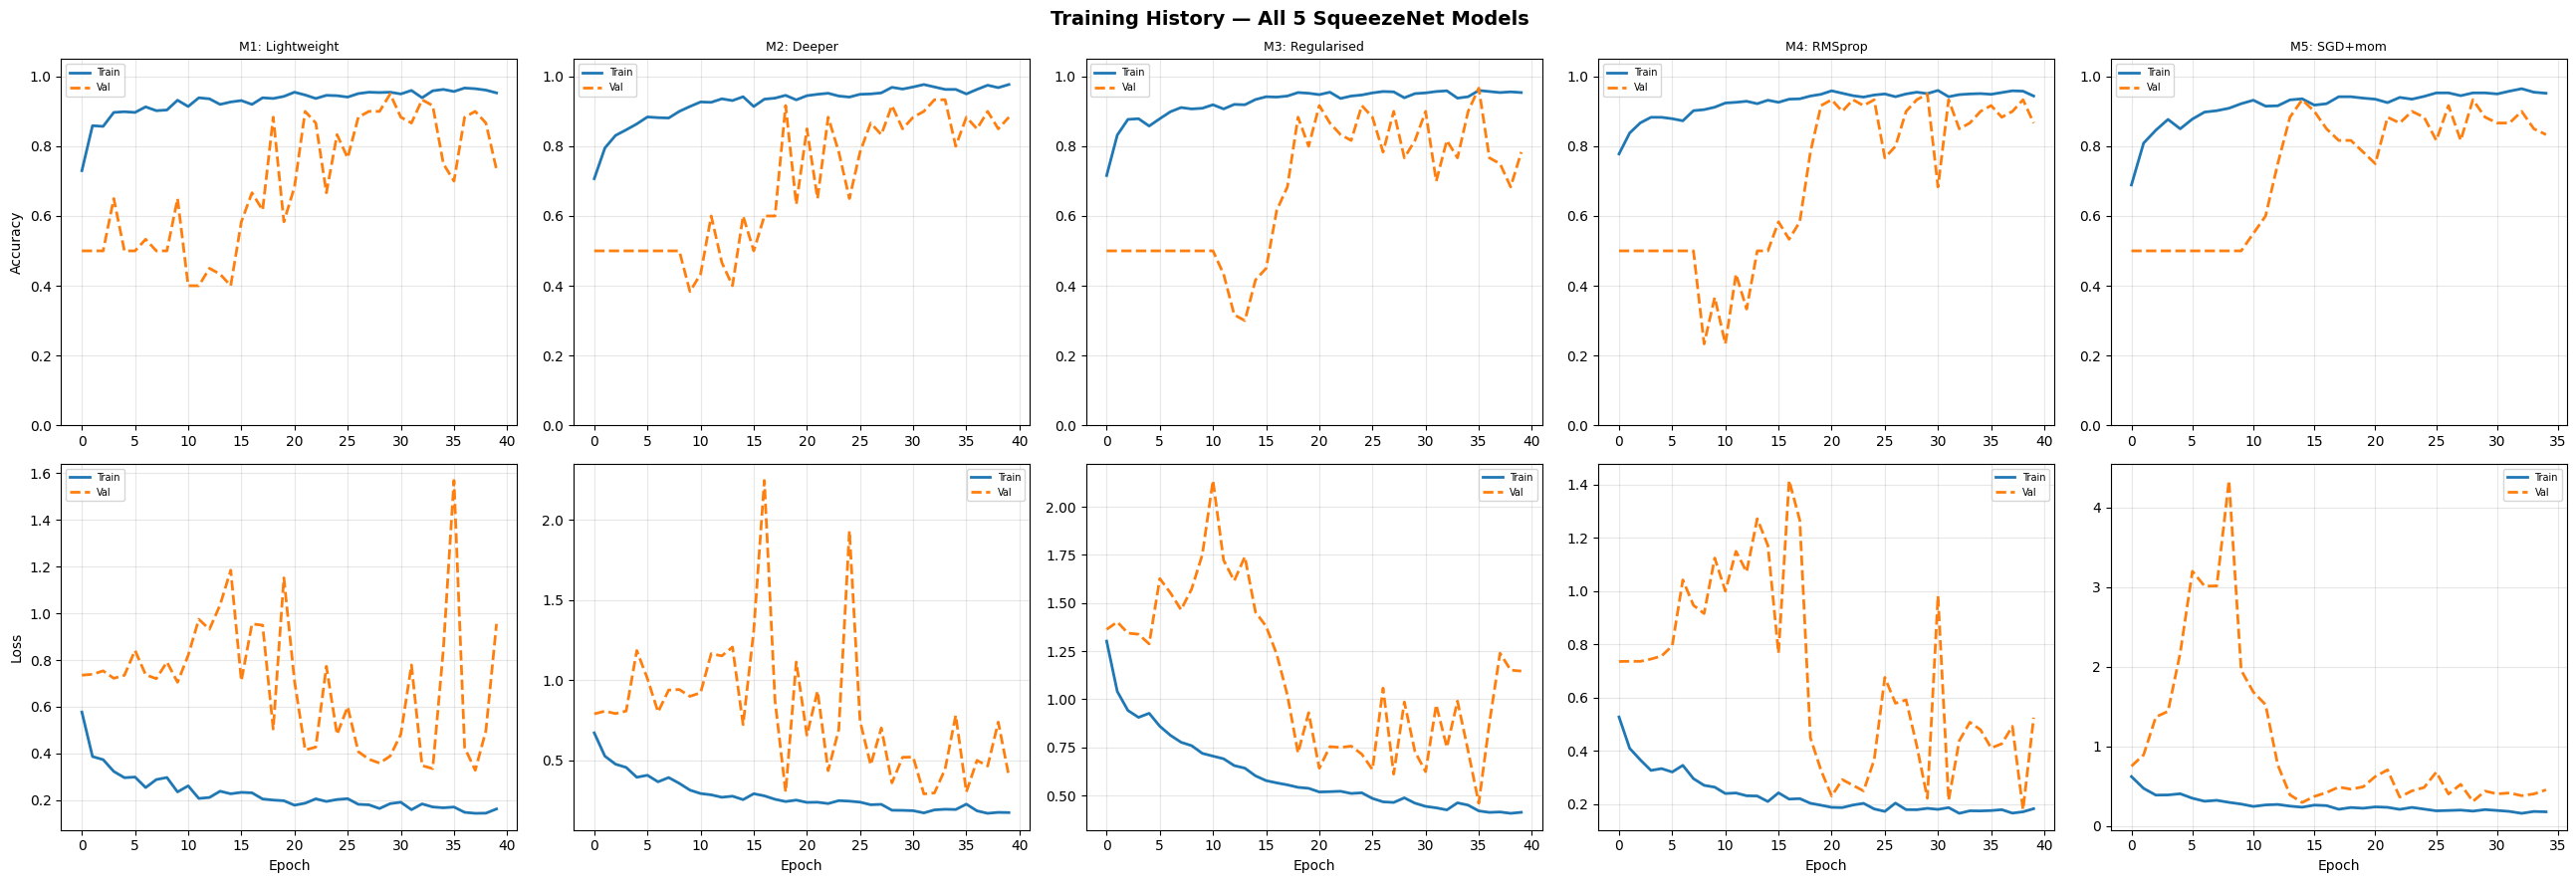

✅ all_models_training_history.png saved


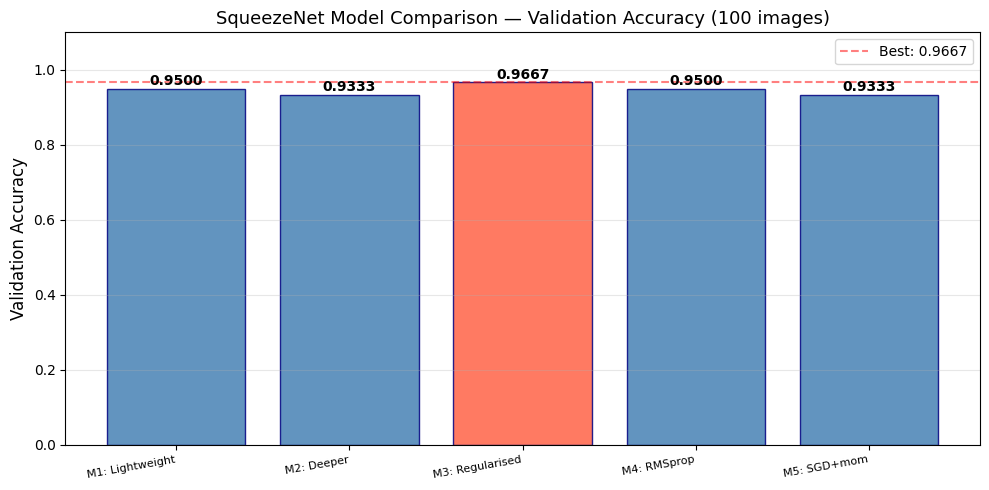

✅ model_comparison_val_accuracy.png saved

🏆 BEST MODEL: model_3 — Regularised (4 Fire modules, Adam lr=1e-3, high L2+drop)
   Validation Accuracy: 0.9667


In [ ]:
# ============================================================================
# CELL 10 — Compare All Models
# ============================================================================
model_labels = [f'M{i}: {MODEL_BUILDERS[i-1][1].split("(")[0].strip()}'
                for i in range(1, 6)]

# Training curves
fig, axes = plt.subplots(2, 5, figsize=(26, 9))
fig.suptitle('Training History — All 5 SqueezeNet Models', fontsize=14, fontweight='bold')

for col, (mname, hist) in enumerate(all_histories.items()):
    ax_acc  = axes[0, col]
    ax_loss = axes[1, col]
    idx     = int(mname.split('_')[1])
    label   = model_labels[idx-1]

    ax_acc.plot(hist['accuracy'],     label='Train', lw=2)
    ax_acc.plot(hist['val_accuracy'], label='Val',   lw=2, linestyle='--')
    ax_acc.set_title(label, fontsize=9)
    ax_acc.set_ylim([0, 1.05])
    ax_acc.set_ylabel('Accuracy' if col == 0 else '')
    ax_acc.legend(fontsize=7); ax_acc.grid(True, alpha=0.3)

    ax_loss.plot(hist['loss'],     label='Train', lw=2)
    ax_loss.plot(hist['val_loss'], label='Val',   lw=2, linestyle='--')
    ax_loss.set_ylabel('Loss' if col == 0 else '')
    ax_loss.set_xlabel('Epoch')
    ax_loss.legend(fontsize=7); ax_loss.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/all_models_training_history.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ all_models_training_history.png saved')

# Validation accuracy bar chart
fig, ax = plt.subplots(figsize=(10, 5))
names   = [f'Model {i}' for i in range(1, 6)]
vals    = [all_val_accs[f'model_{i}'] for i in range(1, 6)]
colours = ['tomato' if v == max(vals) else 'steelblue' for v in vals]
bars    = ax.bar(names, vals, color=colours, edgecolor='navy', alpha=0.85)
ax.set_ylim([0, 1.1]); ax.set_ylabel('Validation Accuracy', fontsize=12)
ax.set_title('SqueezeNet Model Comparison — Validation Accuracy (100 images)', fontsize=13)
ax.axhline(max(vals), color='red', linestyle='--', alpha=0.5, label=f'Best: {max(vals):.4f}')
ax.legend()
for bar, val in zip(bars, vals):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f'{val:.4f}', ha='center', fontweight='bold', fontsize=10)
ax.set_xticks(range(5))
ax.set_xticklabels(model_labels, fontsize=8, rotation=10, ha='right')
ax.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/model_comparison_val_accuracy.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ model_comparison_val_accuracy.png saved')

best_model_name = max(all_val_accs, key=all_val_accs.get)
best_idx        = int(best_model_name.split('_')[1])
print(f'\n🏆 BEST MODEL: {best_model_name} — {MODEL_BUILDERS[best_idx-1][1]}')
print(f'   Validation Accuracy: {all_val_accs[best_model_name]:.4f}')

In [ ]:
# ============================================================================
# CELL 10b — 5-Fold Cross-Validation on Best SqueezeNet Model
# ============================================================================
# Methodology (mirrors cross_val.ipynb):
#   • StratifiedKFold(n_splits=5, shuffle=True, random_state=42) on
#     X_train_c / y_train_c (the pre-segmented, cached training arrays)
#   • Each fold calls builder_fn() for a fresh random-init model — no
#     trained weights carry over between folds (equivalent to fresh_model()
#     in cross_val.ipynb)
#   • validation_data → held-out fold (EarlyStopping monitor ONLY)
#   • reported metric  → accuracy on fixed external val_ds (100 images,
#     NEVER seen during any fold's training — same role as val_ds in
#     cross_val.ipynb)
#   • Callbacks: EarlyStopping(patience=20, min_delta=0.005) +
#                ReduceLROnPlateau(factor=0.5, patience=8) — same as
#                cross_val.ipynb
# ============================================================================

from sklearn.model_selection import StratifiedKFold
import numpy as np, gc
import matplotlib.pyplot as plt

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print(f"\n{'='*70}")
print(f"5-FOLD CROSS-VALIDATION — {best_model_name}: {best_desc}")
print(f"{'='*70}")
print(f"Training data : {len(X_train_c)} images | "
      f"Healthy={np.sum(y_train_c==0)}, Diseased={np.sum(y_train_c==1)}")
print(f"External val  : {len(X_val_c)} images (fixed, never seen in training)")

fold_val_accs = []

for fold, (train_idx, heldout_idx) in enumerate(
        skf.split(X_train_c, y_train_c), start=1):

    print(f"\n  ── Fold {fold}/5 ──────────────────────────────────────────────")

    X_tr_fold = X_train_c[train_idx];   y_tr_fold = y_train_c[train_idx]
    X_held    = X_train_c[heldout_idx]; y_held    = y_train_c[heldout_idx]

    h_tr, d_tr = np.sum(y_tr_fold == 0), np.sum(y_tr_fold == 1)
    h_ho, d_ho = np.sum(y_held == 0),    np.sum(y_held == 1)
    print(f"     Train split : {len(X_tr_fold):5d} images (H={h_tr}, D={d_tr})")
    print(f"     Held-out    : {len(X_held):5d} images (H={h_ho}, D={d_ho})")

    # Fresh model — random weight init; same architecture & optimiser as best
    # (mirrors fresh_model() in cross_val.ipynb but uses builder_fn directly
    #  since we have the builder available in this notebook)
    tf.keras.backend.clear_session()
    gc.collect()
    fold_model = build_model_3()  # builder_fn()

    # Rebuild datasets inside each fold — no stale graph references
    fold_train_ds   = make_dataset(X_tr_fold, y_tr_fold, augment=True,  shuffle=True)
    fold_heldout_ds = make_dataset(X_held,    y_held,    augment=False, shuffle=False)
    # val_ds is already built in CELL 7 and reused here unchanged

    fold_callbacks = [
        keras.callbacks.EarlyStopping(
            monitor='val_accuracy', patience=20, min_delta=0.005,
            restore_best_weights=True, verbose=0),
        keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss', factor=0.5, patience=8,
            min_lr=1e-6, verbose=0),
    ]

    # EarlyStopping monitors held-out fold; val_ds is NEVER seen during training
    fold_model.fit(
        fold_train_ds,
        epochs=EPOCHS,
        validation_data=fold_heldout_ds,
        callbacks=fold_callbacks,
        verbose=1
    )

    # Evaluate on the fixed external val set (unseen throughout all folds)
    _, fold_acc = fold_model.evaluate(val_ds, verbose=0)
    fold_val_accs.append(fold_acc)
    print(f"     Fold {fold} → external val acc: {fold_acc:.4f}")

    del fold_model, fold_train_ds, fold_heldout_ds
    tf.keras.backend.clear_session()
    gc.collect()

# ── Summary ───────────────────────────────────────────────────────────────
avg_cv = np.mean(fold_val_accs)
std_cv = np.std(fold_val_accs)

print(f"\n  {'─'*66}")
print(f"  Cross-Validation Results — {best_desc}")
for i, va in enumerate(fold_val_accs, 1):
    print(f"    Fold {i}: val acc = {va:.4f}")
print(f"  {'─'*66}")
print(f"  CV Accuracy (mean ± std, 5 folds): {avg_cv:.4f} ± {std_cv:.4f}")
print(f"  {'─'*66}")

# ── Bar chart of per-fold accuracies ──────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 5))
folds_labels = [f'Fold {i}' for i in range(1, 6)]
bars = ax.bar(folds_labels, fold_val_accs,
              color='steelblue', edgecolor='navy', alpha=0.85)
ax.axhline(avg_cv, color='tomato', linestyle='--', lw=2,
           label=f'Mean: {avg_cv:.4f} ± {std_cv:.4f}')
ax.set_ylim([0, 1.1])
ax.set_ylabel('External Val Accuracy', fontsize=12)
ax.set_title(f'5-Fold CV — {best_desc}', fontsize=12)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3, axis='y')
for bar, val in zip(bars, fold_val_accs):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.01,
            f'{val:.4f}', ha='center', fontsize=10, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/cross_val_fold_accuracies.png',
            dpi=150, bbox_inches='tight')
plt.show()
print('\u2705 cross_val_fold_accuracies.png saved')


In [ ]:
# ============================================================================
# CELL 11 — Retrain Best Model on Train + Val (100) Combined
# ============================================================================
print('=' * 70)
print(f'🔁 Retraining {best_model_name} on Train + Val combined')
print('=' * 70)

X_trainval_c = np.concatenate([X_train_c, X_val_c])
y_trainval_c = np.concatenate([y_train_c, y_val_c])
h = np.sum(y_trainval_c == 0)
d = np.sum(y_trainval_c == 1)
print(f'Combined: {len(X_trainval_c)} images (Healthy={h}, Diseased={d})')

trainval_ds = make_dataset(X_trainval_c, y_trainval_c, augment=True, shuffle=True)

gc.collect()
tf.keras.backend.clear_session()
print_vram('before final retrain')

builder_fn, best_desc = MODEL_BUILDERS[best_idx - 1]
final_model = builder_fn()

final_callbacks = [
    EarlyStopping(monitor='loss', patience=8,
                  restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='loss', factor=0.5, patience=4,
                     min_lr=1e-6, verbose=1),
    ModelCheckpoint(
        os.path.join(OUTPUT_DIR, 'final_model_best.keras'),
        monitor='loss', save_best_only=True, verbose=0
    )
]

final_history = final_model.fit(
    trainval_ds,
    epochs=EPOCHS,
    callbacks=final_callbacks,
    verbose=1
)

print('\n✅ Final model retraining complete')
print_vram('after final retrain')

🔁 Retraining model_3 on Train + Val combined
Combined: 1060 images (Healthy=530, Diseased=530)
  VRAM [before final retrain] — current: 1249 MB | peak: 1300 MB
Epoch 1/40
34/34 ━━━━━━━━━━━━━━━━━━━━ 31s 414ms/step - accuracy: 0.7396 - loss: 1.1828 - learning_rate: 0.0010
Epoch 2/40
34/34 ━━━━━━━━━━━━━━━━━━━━ 2s 61ms/step - accuracy: 0.8217 - loss: 1.0472 - learning_rate: 0.0010
Epoch 3/40
34/34 ━━━━━━━━━━━━━━━━━━━━ 3s 67ms/step - accuracy: 0.8566 - loss: 0.9576 - learning_rate: 0.0010
Epoch 4/40
34/34 ━━━━━━━━━━━━━━━━━━━━ 2s 53ms/step - accuracy: 0.8519 - loss: 0.9494 - learning_rate: 0.0010
Epoch 5/40
34/34 ━━━━━━━━━━━━━━━━━━━━ 3s 53ms/step - accuracy: 0.8708 - loss: 0.8970 - learning_rate: 0.0010
Epoch 6/40
34/34 ━━━━━━━━━━━━━━━━━━━━ 2s 53ms/step - accuracy: 0.8896 - loss: 0.8232 - learning_rate: 0.0010
Epoch 7/40
34/34 ━━━━━━━━━━━━━━━━━━━━ 3s 53ms/step - accuracy: 0.8981 - loss: 0.7927 - learning_rate: 0.0010
Epoch 8/40
34/34 ━━━━━━━━━━━━━━━━━━━━ 2s 60ms/step - accuracy: 0.9075 - los

📝 FINAL EVALUATION on Test Set (60 held-out images)
2/2 ━━━━━━━━━━━━━━━━━━━━ 6s 3s/step - accuracy: 0.7250 - loss: 1.1600

  Test Accuracy : 0.7250
  Test Loss     : 1.1600

📋 Classification Report:
              precision    recall  f1-score   support

     Healthy       1.00      0.45      0.62        20
    Diseased       0.65      1.00      0.78        20

    accuracy                           0.72        40
   macro avg       0.82      0.72      0.70        40
weighted avg       0.82      0.72      0.70        40



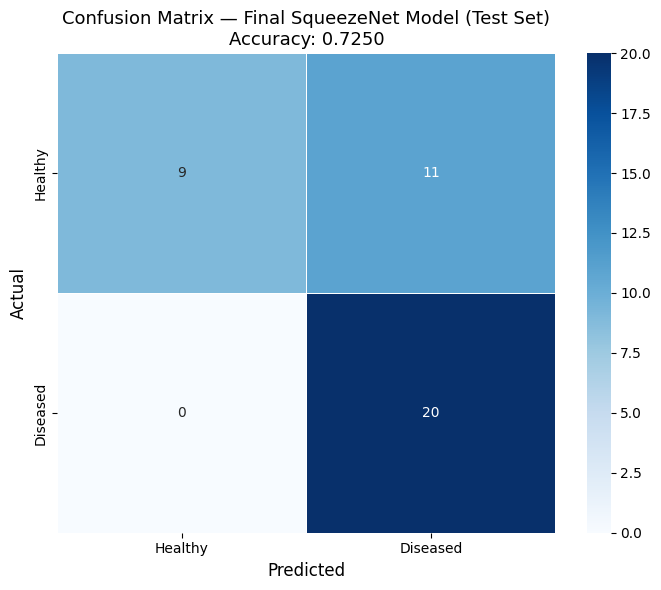

✅ final_model_confusion_matrix.png saved


In [ ]:
# ============================================================================
# CELL 12 — Final Evaluation on Test Set (60 unseen images)
# ============================================================================
print('=' * 70)
print('📝 FINAL EVALUATION on Test Set (60 held-out images)')
print('=' * 70)

test_loss, test_acc = final_model.evaluate(test_ds, verbose=1)
print(f'\n  Test Accuracy : {test_acc:.4f}')
print(f'  Test Loss     : {test_loss:.4f}')

y_pred_prob = final_model.predict(test_ds, verbose=0)
y_pred      = np.argmax(y_pred_prob, axis=1)
y_true      = y_test_c

print('\n📋 Classification Report:')
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES))

cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            linewidths=0.5, ax=ax)
ax.set_title(f'Confusion Matrix — Final SqueezeNet Model (Test Set)\nAccuracy: {test_acc:.4f}', fontsize=13)
ax.set_xlabel('Predicted', fontsize=12)
ax.set_ylabel('Actual',    fontsize=12)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'final_model_confusion_matrix.png'),
            dpi=150, bbox_inches='tight')
plt.show()
print('✅ final_model_confusion_matrix.png saved')

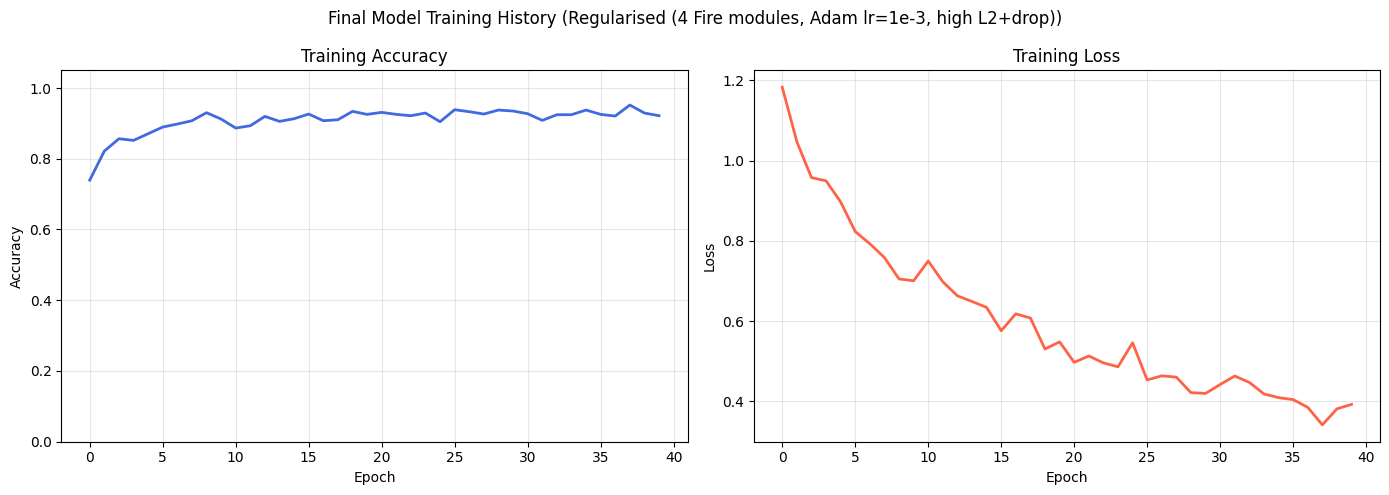

✅ final_model_training_history.png saved


In [ ]:
# ============================================================================
# CELL 13 — Final Model Training History
# ============================================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle(f'Final Model Training History ({best_desc})', fontsize=12)

axes[0].plot(final_history.history['accuracy'], lw=2, color='royalblue')
axes[0].set_title('Training Accuracy')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Accuracy')
axes[0].set_ylim([0, 1.05]); axes[0].grid(True, alpha=0.3)

axes[1].plot(final_history.history['loss'], lw=2, color='tomato')
axes[1].set_title('Training Loss')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Loss')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'final_model_training_history.png'),
            dpi=150, bbox_inches='tight')
plt.show()
print('✅ final_model_training_history.png saved')

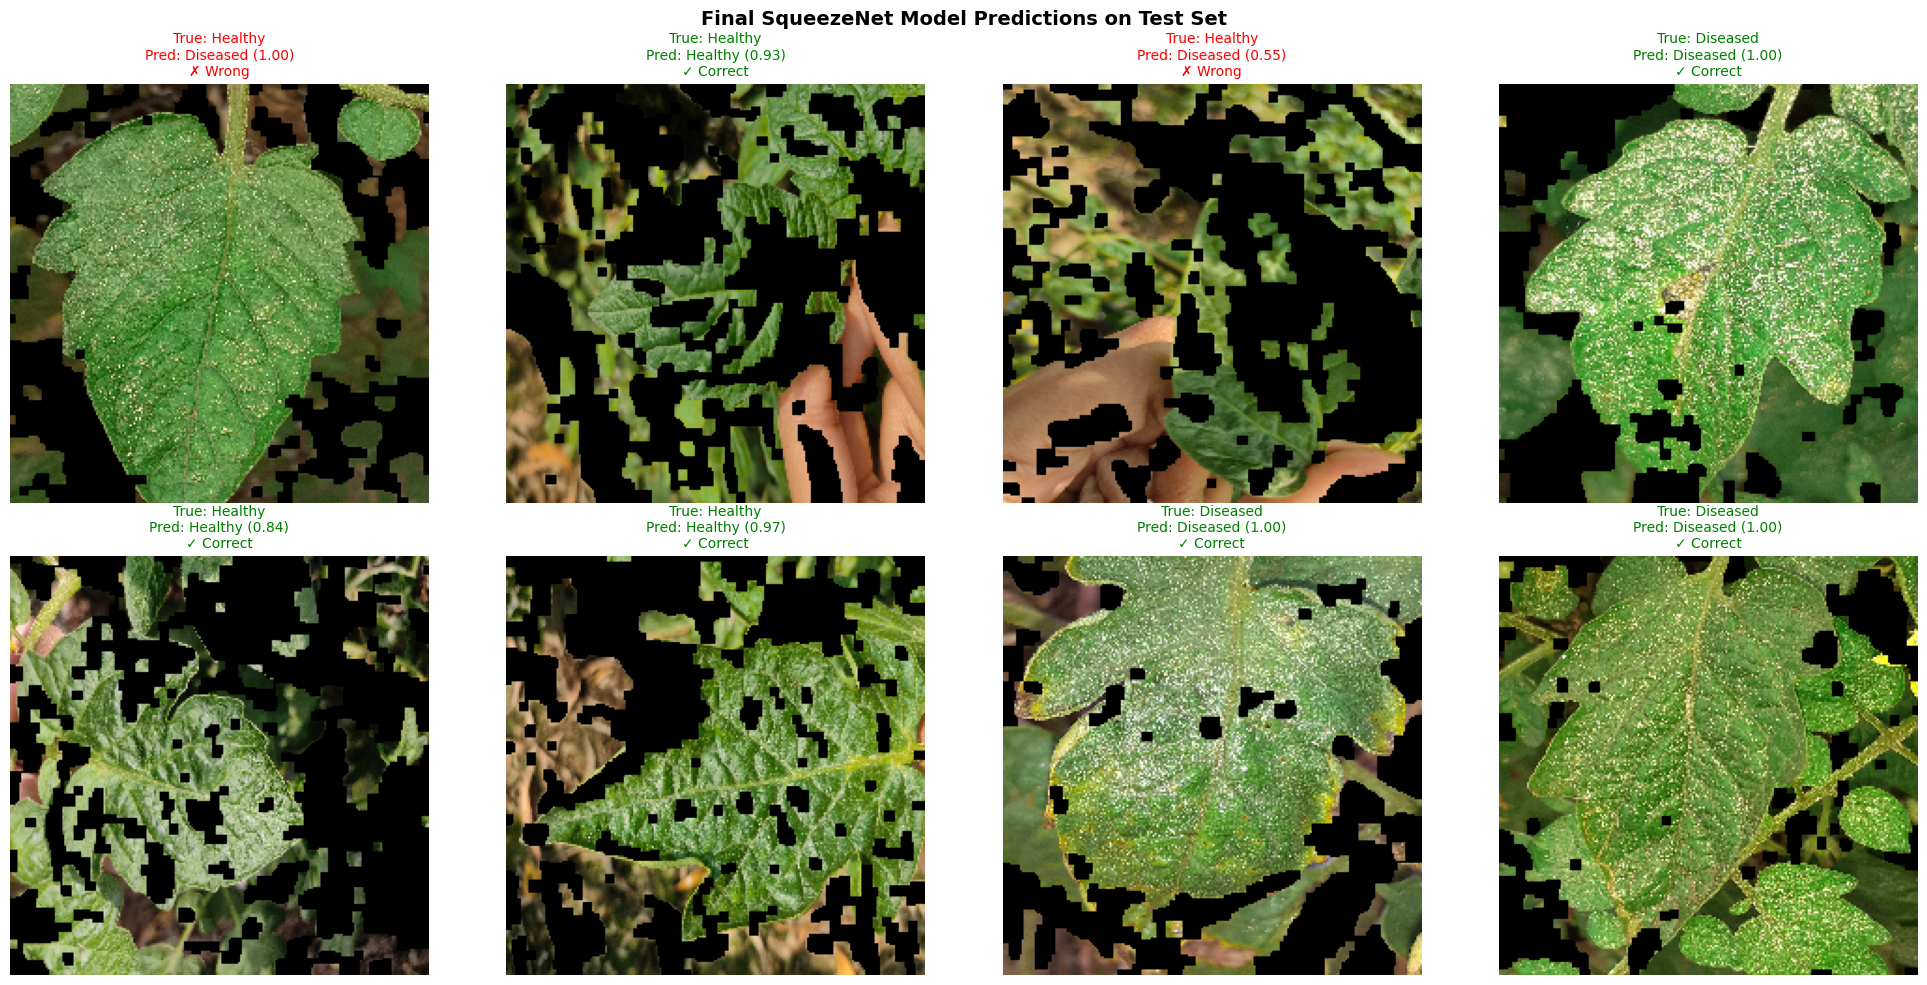

✅ final_model_predictions.png saved


In [ ]:
# ============================================================================
# CELL 14 — Prediction Visualisation on Test Images
# ============================================================================
def visualise_predictions(model, X_cached, true_labels, n=8, title=''):
    idxs = np.random.choice(len(X_cached), min(n, len(X_cached)), replace=False)
    cols = 4
    rows = int(np.ceil(len(idxs) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 5, rows * 5))
    axes = axes.flatten()
    fig.suptitle(title, fontsize=14, fontweight='bold')
    for i, idx in enumerate(idxs):
        img_display = (X_cached[idx] * 255).astype(np.uint8)
        inp         = X_cached[idx:idx+1]
        probs       = model.predict(inp, verbose=0)[0]
        pred_cls    = np.argmax(probs)
        confidence  = probs[pred_cls]
        correct     = pred_cls == true_labels[idx]
        axes[i].imshow(img_display)
        axes[i].set_title(
            f"True: {CLASS_NAMES[true_labels[idx]]}\n"
            f"Pred: {CLASS_NAMES[pred_cls]} ({confidence:.2f})\n"
            f"{'✓ Correct' if correct else '✗ Wrong'}",
            color='green' if correct else 'red', fontsize=10
        )
        axes[i].axis('off')
    for j in range(len(idxs), len(axes)):
        axes[j].axis('off')
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, 'final_model_predictions.png'),
                dpi=150, bbox_inches='tight')
    plt.show()
    print('✅ final_model_predictions.png saved')

visualise_predictions(
    final_model, X_test_c, y_test_c,
    n=8, title='Final SqueezeNet Model Predictions on Test Set'
)


📊 COMPLETE RESULTS SUMMARY

Model        Val Accuracy Description
----------------------------------------------------------------------
  Model 1       0.9500 Lightweight (4 Fire modules, Adam lr=1e-3)
  Model 2       0.9333 Deeper      (6 Fire modules, Adam lr=5e-4)
  Model 3       0.9667 Regularised (4 Fire modules, Adam lr=1e-3, high L2+drop) ← BEST
  Model 4       0.9500 RMSprop     (4 Fire modules, RMSprop lr=5e-4)
  Model 5       0.9333 SGD+mom     (6 Fire modules, SGD lr=1e-2, momentum=0.9)

----------------------------------------------------------------------
  Best Model   : model_3 — Regularised (4 Fire modules, Adam lr=1e-3, high L2+drop)
  Val Acc      : 0.9667
  Test Acc     : 0.7250
  Test Loss    : 1.1600
  Best Channel : saturation
----------------------------------------------------------------------


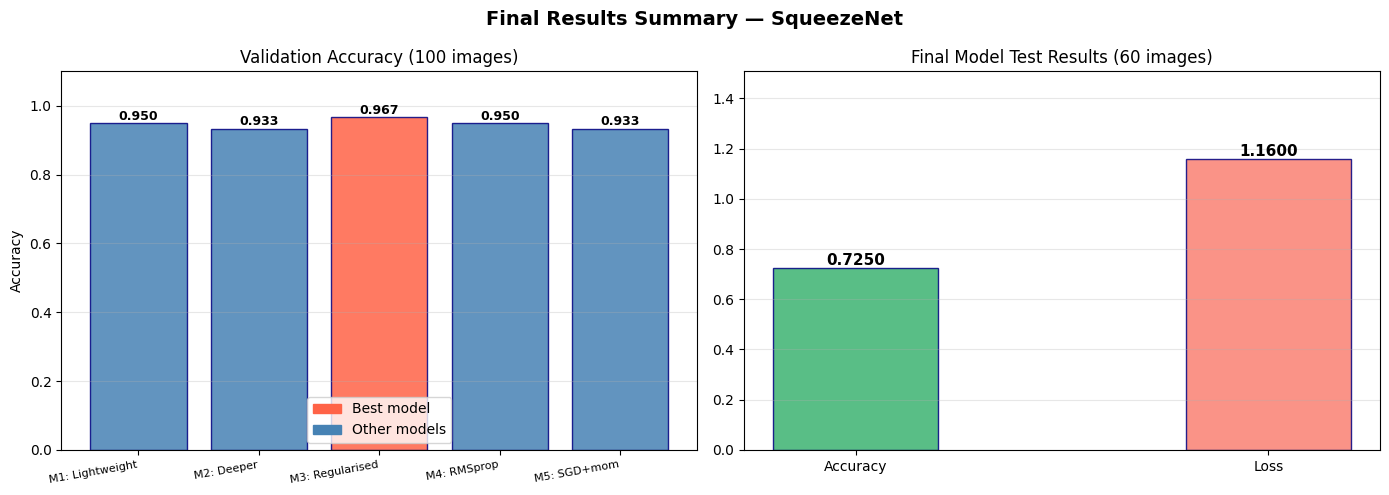

✅ final_summary.png saved
✅ results.json saved
✅ final_model.keras saved

✅ PROJECT COMPLETE

  Output files in: /content/squeezenet_output
  all_models_training_history.png               383.1 KB
  dataset_split.png                             34.1 KB
  final_model.keras                             2090.5 KB
  final_model_best.keras                        2090.5 KB
  final_model_confusion_matrix.png              46.5 KB
  final_model_predictions.png                   4151.0 KB
  final_model_training_history.png              77.6 KB
  final_summary.png                             87.5 KB
  model_1_best.keras                            959.3 KB
  model_1_weights.weights.h5                    914.9 KB
  model_2_best.keras                            4462.0 KB
  model_2_weights.weights.h5                    4398.9 KB
  model_3_best.keras                            2090.5 KB
  model_3_weights.weights.h5                    2046.3 KB
  model_4_best.keras                            694.1 KB
  

In [ ]:
# ============================================================================
# CELL 15 — Full Results Summary
# ============================================================================
print('\n' + '='*70)
print('📊 COMPLETE RESULTS SUMMARY')
print('='*70)
print(f"\n{'Model':<10} {'Val Accuracy':>14} Description")
print('-' * 70)
for i in range(1, 6):
    mname  = f'model_{i}'
    acc    = all_val_accs[mname]
    desc   = MODEL_BUILDERS[i-1][1]
    marker = ' ← BEST' if mname == best_model_name else ''
    print(f'  Model {i} {acc:>12.4f} {desc}{marker}')

print('\n' + '-'*70)
print(f'  Best Model   : {best_model_name} — {best_desc}')
print(f'  Val Acc      : {all_val_accs[best_model_name]:.4f}')
print(f'  Test Acc     : {test_acc:.4f}')
print(f'  Test Loss    : {test_loss:.4f}')
print(f'  Best Channel : {best_channel}')
print('-'*70)

# Comparison charts
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Final Results Summary — SqueezeNet', fontsize=14, fontweight='bold')

model_names = [f'Model {i}' for i in range(1, 6)]
val_accs    = [all_val_accs[f'model_{i}'] for i in range(1, 6)]
colours     = ['tomato' if f'model_{i}' == best_model_name else 'steelblue'
               for i in range(1, 6)]

bars = axes[0].bar(model_names, val_accs, color=colours, edgecolor='navy', alpha=0.85)
axes[0].set_ylim([0, 1.1])
axes[0].set_ylabel('Accuracy')
axes[0].set_title('Validation Accuracy (100 images)')
axes[0].set_xticks(range(5))
axes[0].set_xticklabels(model_labels, fontsize=8, rotation=10, ha='right')
axes[0].grid(True, alpha=0.3, axis='y')
for bar, val in zip(bars, val_accs):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                 f'{val:.3f}', ha='center', fontsize=9, fontweight='bold')
axes[0].legend(handles=[
    mpatches.Patch(color='tomato',    label='Best model'),
    mpatches.Patch(color='steelblue', label='Other models')
])

metrics = ['Accuracy', 'Loss']
values  = [test_acc, test_loss]
bars2   = axes[1].bar(metrics, values, color=['mediumseagreen','salmon'],
                      edgecolor='navy', alpha=0.85, width=0.4)
axes[1].set_ylim([0, max(values) * 1.3])
axes[1].set_title('Final Model Test Results (60 images)')
axes[1].grid(True, alpha=0.3, axis='y')
for bar, val in zip(bars2, values):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                 f'{val:.4f}', ha='center', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'final_summary.png'), dpi=150, bbox_inches='tight')
plt.show()
print('✅ final_summary.png saved')

# Save JSON results
results = {
    'architecture'         : 'SqueezeNet (Fire modules)',
    'best_channel'         : best_channel,
    'dataset'              : {
        'train': int(len(X_train)), 'val': int(len(X_val)), 'test': int(len(X_test))
    },
    'model_val_accuracies' : {k: float(v) for k, v in all_val_accs.items()},
    'best_model'           : best_model_name,
    'best_model_description': best_desc,
    'final_test_accuracy'  : float(test_acc),
    'final_test_loss'      : float(test_loss)
}
with open(os.path.join(OUTPUT_DIR, 'results.json'), 'w') as f:
    json.dump(results, f, indent=4)
print('✅ results.json saved')

final_model.save(os.path.join(OUTPUT_DIR, 'final_model.keras'))
print('✅ final_model.keras saved')

print('\n' + '='*70)
print('✅ PROJECT COMPLETE')
print('='*70)
print(f'\n  Output files in: {OUTPUT_DIR}')
for fname in sorted(os.listdir(OUTPUT_DIR)):
    size = os.path.getsize(os.path.join(OUTPUT_DIR, fname))
    print(f'  {fname:<45} {size/1024:.1f} KB')

In [ ]:
# ============================================================================
# FINAL METRICS — Precision, Recall, F1 (Overall)
# ============================================================================
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score

y_pred_prob = final_model.predict(test_ds, verbose=0)
y_pred      = np.argmax(y_pred_prob, axis=1)
y_true      = y_test_c

precision = precision_score(y_true, y_pred, average='weighted', zero_division=0)
recall    = recall_score(y_true, y_pred, average='weighted', zero_division=0)
f1        = f1_score(y_true, y_pred, average='weighted', zero_division=0)
accuracy  = accuracy_score(y_true, y_pred)

print("=" * 40)
print("      OVERALL MODEL METRICS")
print("=" * 40)
print(f"  Accuracy  : {accuracy:.4f}")
print(f"  Precision : {precision:.4f}")
print(f"  Recall    : {recall:.4f}")
print(f"  F1 Score  : {f1:.4f}")
print("=" * 40)

      OVERALL MODEL METRICS
  Accuracy  : 0.7250
  Precision : 0.8226
  Recall    : 0.7250
  F1 Score  : 0.7025


📈 TRAINING ACCURACY SUMMARY — ALL 5 MODELS

Model      Description                                   Best Train Acc  @ Epoch Final Train Acc  Best Val Acc
--------------------------------------------------------------------------------------------------------------
  Model 1  Lightweight (4 Fire modules, Adam lr=1e-3)           0.9670       37          0.9530        0.9500
  Model 2  Deeper      (6 Fire modules, Adam lr=5e-4)           0.9770       32          0.9770        0.9333
  Model 3  Regularised (4 Fire modules, Adam lr=1e-3, high L2+drop)        0.9600       36          0.9540        0.9667 ← BEST VAL
  Model 4  RMSprop     (4 Fire modules, RMSprop lr=5e-4)        0.9600       31          0.9440        0.9500
  Model 5  SGD+mom     (6 Fire modules, SGD lr=1e-2, momentum=0.9)        0.9650       33          0.9520        0.9333
--------------------------------------------------------------------------------------------------------------


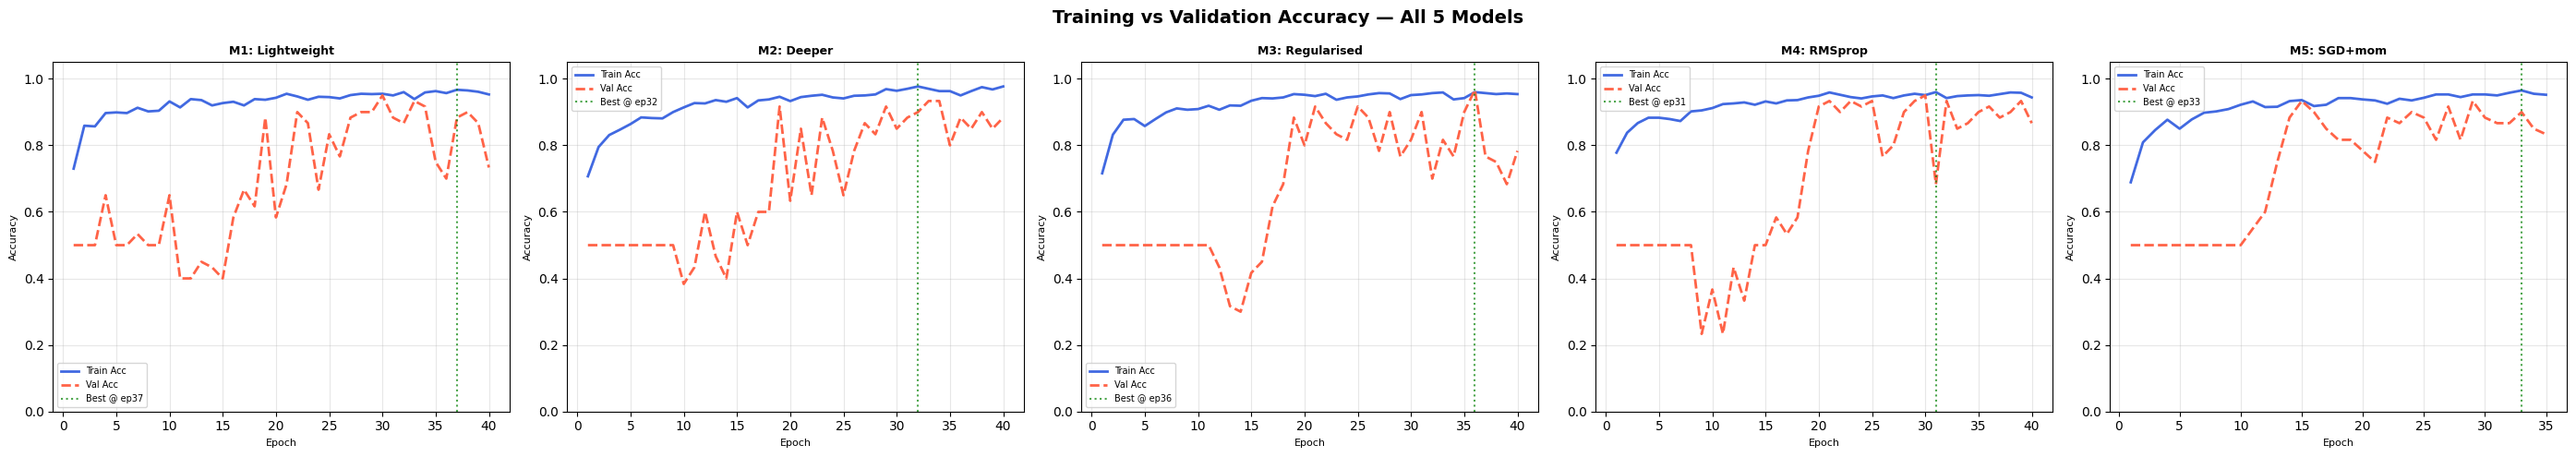


✅ training_accuracy_all_models.png saved


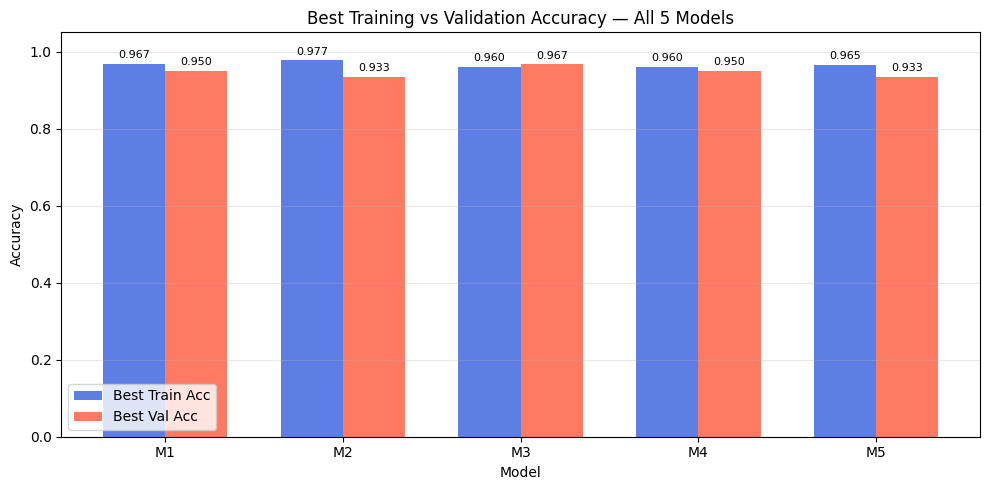

✅ training_vs_val_accuracy_bar.png saved


In [ ]:
# ============================================================================
# CELL — Training Accuracy Summary (add after Cell 9 / Train All 5 Models)
# ============================================================================
# Shows per-model: best training accuracy, final training accuracy,
# best validation accuracy, and the epoch each peak was reached.
# Also plots training vs validation accuracy curves for all 5 models.
# ============================================================================

import matplotlib.pyplot as plt
import numpy as np

print('=' * 70)
print('📈 TRAINING ACCURACY SUMMARY — ALL 5 MODELS')
print('=' * 70)
print(f"\n{'Model':<10} {'Description':<45} {'Best Train Acc':>14} {'@ Epoch':>8} {'Final Train Acc':>15} {'Best Val Acc':>13}")
print('-' * 110)

for i in range(1, 6):
    mname      = f'model_{i}'
    hist       = all_histories[mname]
    desc       = MODEL_BUILDERS[i - 1][1]
    train_accs = hist['accuracy']
    val_accs   = hist.get('val_accuracy', [])

    best_train_acc   = max(train_accs)
    best_train_epoch = train_accs.index(best_train_acc) + 1
    final_train_acc  = train_accs[-1]
    best_val_acc     = max(val_accs) if val_accs else float('nan')

    marker = ' ← BEST VAL' if mname == best_model_name else ''
    print(f"  Model {i}  {desc:<45} {best_train_acc:>13.4f}  {best_train_epoch:>7}  {final_train_acc:>14.4f}  {best_val_acc:>12.4f}{marker}")

print('-' * 110)

# ── Training vs Validation Accuracy Curves ──────────────────────────────────
fig, axes = plt.subplots(1, 5, figsize=(28, 5))
fig.suptitle('Training vs Validation Accuracy — All 5 Models', fontsize=14, fontweight='bold')

for i, ax in enumerate(axes, 1):
    mname      = f'model_{i}'
    hist       = all_histories[mname]
    desc       = MODEL_BUILDERS[i - 1][1].split('(')[0].strip()
    train_accs = hist['accuracy']
    val_accs   = hist.get('val_accuracy', [])
    epochs_ran = range(1, len(train_accs) + 1)

    ax.plot(epochs_ran, train_accs, lw=2, color='royalblue',  label='Train Acc')
    if val_accs:
        ax.plot(epochs_ran, val_accs,   lw=2, color='tomato', linestyle='--', label='Val Acc')

    best_ep = train_accs.index(max(train_accs)) + 1
    ax.axvline(best_ep, color='green', linestyle=':', alpha=0.7, label=f'Best @ ep{best_ep}')

    ax.set_title(f'M{i}: {desc}', fontsize=9, fontweight='bold')
    ax.set_xlabel('Epoch', fontsize=8)
    ax.set_ylabel('Accuracy', fontsize=8)
    ax.set_ylim([0, 1.05])
    ax.legend(fontsize=7)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/training_accuracy_all_models.png', dpi=150, bbox_inches='tight')
plt.show()
print('\n✅ training_accuracy_all_models.png saved')

# ── Final Training Accuracy Bar Chart ───────────────────────────────────────
labels      = [f"M{i}" for i in range(1, 6)]
best_trains = [max(all_histories[f'model_{i}']['accuracy']) for i in range(1, 6)]
best_vals   = [max(all_histories[f'model_{i}'].get('val_accuracy', [0])) for i in range(1, 6)]

x   = np.arange(len(labels))
w   = 0.35
fig, ax = plt.subplots(figsize=(10, 5))
bars1 = ax.bar(x - w/2, best_trains, w, label='Best Train Acc', color='royalblue',  alpha=0.85)
bars2 = ax.bar(x + w/2, best_vals,   w, label='Best Val Acc',   color='tomato',     alpha=0.85)

ax.set_xlabel('Model')
ax.set_ylabel('Accuracy')
ax.set_title('Best Training vs Validation Accuracy — All 5 Models')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylim([0, 1.05])
ax.legend()
ax.grid(axis='y', alpha=0.3)

for bar in bars1:
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.01,
            f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=8)
for bar in bars2:
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.01,
            f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/training_vs_val_accuracy_bar.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ training_vs_val_accuracy_bar.png saved')
